In [31]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt


In [32]:
df = pd.read_csv("Ice_cream selling data.csv")

In [33]:
df.corr()

,Temperature (°C),Ice Cream Sales (units)
Temperature (°C),1.000000,-0.175184
Ice Cream Sales (units),-0.175184,1.000000


In [34]:
x = df['Temperature (°C)']
y = df[["Ice Cream Sales (units)"]]

In [35]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,train_size=0.8,random_state=0) 

In [36]:
xtrain

11   -2.288264
31    1.850552
33    2.075101
27    1.024181
48    4.899032
2    -4.213985
46    4.130868
18   -0.673753
15   -1.326379
28    1.240712
22    0.008608
16   -1.173123
41    3.270044
20   -0.036156
42    3.316073
8    -2.672461
13   -1.818938
25    0.693599
5    -3.455712
17   -0.773330
35    2.471946
14   -1.660348
38    2.959932
1    -4.316559
12   -2.111870
43    3.335932
24    0.688781
6    -3.108440
23    0.149245
36    2.784836
21   -0.033895
19   -0.149635
9    -2.652287
39    3.020874
45    3.704057
3    -3.949661
0    -4.662263
47    4.133534
44    3.610778
Name: Temperature (°C), dtype: float64

In [37]:
model=LinearRegression()

In [38]:
xtrain = xtrain.to_frame()

In [39]:
model.fit(xtrain,ytrain)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[-0.45]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Temperature (°C)']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[16.79]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [40]:
model.intercept_

array([16.7907651])

In [41]:
model.coef_

array([[-0.44555267]])

In [42]:
ytrain_predicted = model.predict(xtrain)

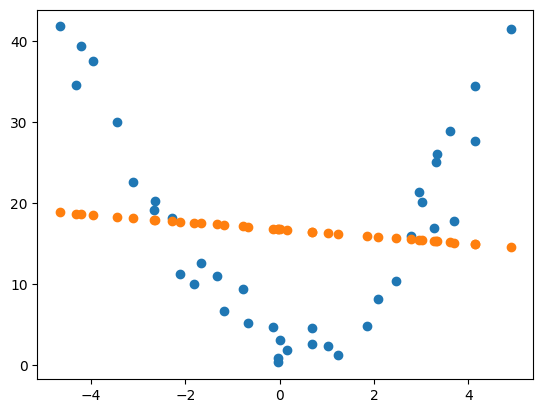

In [43]:
plt.scatter(xtrain,ytrain) # actual input vs actual output
plt.scatter(xtrain,ytrain_predicted) # actual input vs predicted output

Conclusion:

Model is not able to capture the pattern.

Reason:

the data is the non linear and linear regression can capture on;ly linear data


why we're comparing this ?
1. plt.scatter(xtrain,ytrain)
2. plt.scatter(xtrain,ytrain_pertected)

Answer:

From this comparision between actual pattern and pridicted pattern, we can conclue how well the model captures the pattern during model training.

In [44]:
xtest = xtest.to_frame()

In [45]:
ytest_predicted = model.predict(xtest)

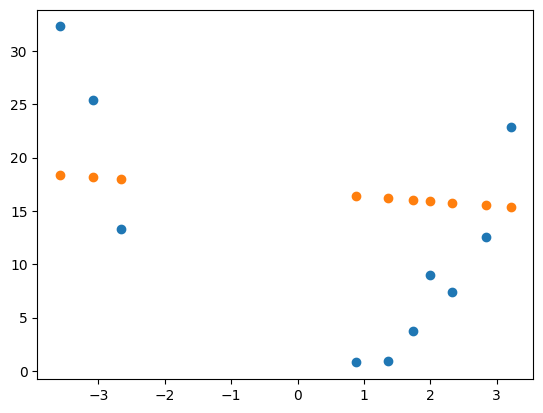

In [46]:
plt.scatter(xtest,ytest) # actual input vs actual output
plt.scatter(xtest,ytest_predicted) # actual input vs predicted output

why we are compaRING this?


In [47]:
train_data = pd.DataFrame({
    'xtrain':xtrain['Temperature (°C)'].to_numpy().ravel(),
    'Ytrain':ytrain.to_numpy().ravel(),
    'Ytrain_pred': ytrain_predicted.ravel()
    })

train_data['Error'] = train_data['Ytrain'] - train_data['Ytrain_pred']

In [48]:
train_data

,xtrain,Ytrain,Ytrain_pred,Error
0,-2.288264,18.123991,17.810307,0.313684
1,1.850552,4.857988,15.966247,-11.108259
2,2.075101,8.170735,15.866199,-7.695464
3,1.024181,2.313806,16.334439,-14.020632
4,4.899032,41.514822,14.607989,26.906833
5,-4.213985,39.383001,18.668317,20.714684
6,4.130868,34.530743,14.950246,19.580497
7,-0.673753,5.210163,17.090957,-11.880795
8,-1.326379,10.957731,17.381737,-6.424005
9,1.240712,1.292361,16.237963,-14.945602
